# Tugas Studi Kasus Data Mining: Regresi Valuasi Real Estat

**Mata Kuliah:** Data Mining  
**Kelas:** A11.4513  
**Penyusun:** Brian Aryansyah Pamungkas  
**NIM:** A11.2024.15880  
**Dataset:** *Real estate valuation data set.xlsx* (UCI Machine Learning Repository: kasus regresi)  
**Variabel target:** `Y house price of unit area`

## Ringkasan Tahapan Pengerjaan

1. **Tahap 1**: Menyiapkan judul, identitas, impor pustaka, dan pengaturan tampilan.
2. **Tahap 2**: Memuat dataset dan melakukan eksplorasi awal (dimensi, tipe data, nilai kosong, statistik deskriptif, cuplikan data).
3. **Tahap 3**: Menentukan fitur prediktor `X` dan variabel target `y`, serta menjelaskan alasan kolom `No` dihapus.
4. **Tahap 4**: Membagi data menjadi data latih dan data uji (80:20) serta menerapkan `StandardScaler`.
5. **Tahap 5**: Membuat fungsi evaluasi kinerja untuk RMSE, MAE, MAPE, dan R².
6. **Tahap 6**: Melatih model Regresi Linier, menampilkan intersep dan koefisien, menuliskan persamaan, lalu mengevaluasi kinerjanya.
7. **Tahap 7**: Melatih model k-NN untuk `k = 2, 3, 5, 7, 9` dan membandingkan kinerjanya.
8. **Tahap 8**: Membandingkan seluruh model melalui tabel dan grafik, lalu memilih model terbaik.
9. **Tahap 9**: Merekap jawaban akhir untuk soal nomor 1, 2, dan 3.

> **Catatan metodologis:** Seluruh proses menggunakan pembagian data dan *random state* yang sama sehingga perbandingan antarmodel dilakukan pada data uji yang identik. Penskalaan fitur hanya di-*fit* pada data latih untuk mencegah kebocoran data (*data leakage*).

In [1]:
# ============================================================
# Tahap 1: Impor pustaka dan pengaturan tampilan
# ============================================================
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from IPython.display import display

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    mean_absolute_percentage_error,
    r2_score,
)

# Pengaturan tampilan angka dan tabel
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
np.set_printoptions(precision=4, suppress=True)

# Pengaturan visualisasi
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.labelsize"] = 11
plt.rcParams["axes.titleweight"] = "bold"

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("Pustaka berhasil diimpor.")
print(f"pandas {pd.__version__} | numpy {np.__version__} | scikit-learn {__import__('sklearn').__version__}")

Pustaka berhasil diimpor.
pandas 3.0.2 | numpy 2.4.4 | scikit-learn 1.9.0


## Tahap 2: Pemuatan Dataset dan Eksplorasi Awal

Dataset yang digunakan adalah **Real Estate Valuation** dari UCI Machine Learning Repository. Dataset ini berisi 414 observasi transaksi properti di Distrik Sindian, New Taipei City, Taiwan.

Pada tahap ini dilakukan:
- pemuatan berkas Excel (dengan cadangan tautan UCI apabila berkas lokal tidak tersedia),
- pemeriksaan dimensi data,
- pemeriksaan nama kolom dan tipe data,
- pemeriksaan nilai kosong,
- statistik deskriptif,
- dan cuplikan data.

In [2]:
# ============================================================
# Tahap 2: Pemuatan dataset dan eksplorasi awal
# ============================================================
DATA_FILENAME = "Real estate valuation data set.xlsx"
DATA_URL = (
    "https://archive.ics.uci.edu/ml/machine-learning-databases/"
    "00477/Real%20estate%20valuation%20data%20set.xlsx"
)

data_path = Path(DATA_FILENAME)

if data_path.exists():
    df = pd.read_excel(data_path)
    print(f"Dataset dimuat dari berkas lokal: {data_path.resolve()}")
else:
    print("Berkas lokal tidak ditemukan. Mengunduh dari repositori UCI ...")
    df = pd.read_excel(DATA_URL)
    df.to_excel(DATA_FILENAME, index=False)
    print(f"Dataset diunduh dan disimpan sebagai: {DATA_FILENAME}")

print(f"\nDimensi dataset (baris, kolom): {df.shape}")

print("\nNama kolom:")
for i, col in enumerate(df.columns, start=1):
    print(f"  {i}. {col}")

print("\n=== Informasi struktur data ===")
df.info()

print("\n=== Jumlah nilai kosong per kolom ===")
print(df.isnull().sum().to_string())

print("\n=== Statistik deskriptif ===")
display(df.describe().T)

print("\n=== Cuplikan lima baris pertama ===")
display(df.head())

Dataset dimuat dari berkas lokal: D:\UDINUS\SEMESTER 5\DATA MINING\TUGAS\Study Case Real Estate\Real estate valuation data set.xlsx

Dimensi dataset (baris, kolom): (414, 8)

Nama kolom:
  1. No
  2. X1 transaction date
  3. X2 house age
  4. X3 distance to the nearest MRT station
  5. X4 number of convenience stores
  6. X5 latitude
  7. X6 longitude
  8. Y house price of unit area

=== Informasi struktur data ===


<class 'pandas.DataFrame'>
RangeIndex: 414 entries, 0 to 413
Data columns (total 8 columns):
 #   Column                                  Non-Null Count  Dtype  
---  ------                                  --------------  -----  
 0   No                                      414 non-null    int64  
 1   X1 transaction date                     414 non-null    float64
 2   X2 house age                            414 non-null    float64
 3   X3 distance to the nearest MRT station  414 non-null    float64
 4   X4 number of convenience stores         414 non-null    int64  
 5   X5 latitude                             414 non-null    float64
 6   X6 longitude                            414 non-null    float64
 7   Y house price of unit area              414 non-null    float64
dtypes: float64(6), int64(2)
memory usage: 26.0 KB

=== Jumlah nilai kosong per kolom ===
No                                        0
X1 transaction date                       0
X2 house age                           

,count,mean,std,min,25%,50%,75%,max
No,414.0000,207.5000,119.6558,1.0000,104.2500,207.5000,310.7500,414.0000
X1 transaction date,414.0000,"2,013.1490",0.2820,"2,012.6667","2,012.9167","2,013.1667","2,013.4167","2,013.5833"
X2 house age,414.0000,17.7126,11.3925,0.0000,9.0250,16.1000,28.1500,43.8000
X3 distance to the nearest MRT station,414.0000,"1,083.8857","1,262.1096",23.3828,289.3248,492.2313,"1,454.2790","6,488.0210"
X4 number of convenience stores,414.0000,4.0942,2.9456,0.0000,1.0000,4.0000,6.0000,10.0000
X5 latitude,414.0000,24.9690,0.0124,24.9321,24.9630,24.9711,24.9775,25.0146
X6 longitude,414.0000,121.5334,0.0153,121.4735,121.5281,121.5386,121.5433,121.5663
Y house price of unit area,414.0000,37.9802,13.6065,7.6000,27.7000,38.4500,46.6000,117.5000



=== Cuplikan lima baris pertama ===


,No,X1 transaction date,X2 house age,X3 distance to the nearest MRT station,X4 number of convenience stores,X5 latitude,X6 longitude,Y house price of unit area
0,1,"2,012.9167",32.0000,84.8788,10,24.9830,121.5402,37.9000
1,2,"2,012.9167",19.5000,306.5947,9,24.9803,121.5395,42.2000
2,3,"2,013.5833",13.3000,561.9845,5,24.9875,121.5439,47.3000
3,4,"2,013.5000",13.3000,561.9845,5,24.9875,121.5439,54.8000
4,5,"2,012.8333",5.0000,390.5684,5,24.9794,121.5425,43.1000


### Interpretasi Eksplorasi Awal

- Dataset memiliki **414 baris** dan **8 kolom**: satu kolom identitas (`No`), enam fitur prediktor (`X1` sampai `X6`), dan satu variabel target (`Y house price of unit area`).
- Seluruh kolom bertipe numerik (`int64` atau `float64`), sehingga tidak diperlukan *encoding* variabel kategorikal.
- **Tidak ada nilai kosong** pada seluruh kolom, sehingga tidak diperlukan imputasi.
- Skala antarfitur sangat berbeda. Sebagai contoh, `X3 distance to the nearest MRT station` berada pada skala ratusan hingga ribuan meter, sedangkan `X4 number of convenience stores` hanya bernilai satuan. Perbedaan skala ini menjadi alasan pentingnya penskalaan fitur, terutama untuk algoritma berbasis jarak seperti k-NN.
- Variabel target `Y house price of unit area` memiliki rentang yang cukup lebar, sehingga evaluasi akan menggunakan beberapa metrik sekaligus agar interpretasi tidak bergantung pada satu ukuran saja.

## Tahap 3: Penentuan Fitur (X) dan Variabel Target (y) [Soal 1.a]

### Fitur prediktor `X`

Fitur prediktor yang digunakan adalah:

| Kode | Nama Kolom | Keterangan |
|---|---|---|
| `X1` | `X1 transaction date` | Tanggal transaksi yang dinyatakan dalam tahun desimal |
| `X2` | `X2 house age` | Usia rumah (tahun) |
| `X3` | `X3 distance to the nearest MRT station` | Jarak ke stasiun MRT terdekat (meter) |
| `X4` | `X4 number of convenience stores` | Jumlah minimarket dalam radius tertentu |
| `X5` | `X5 latitude` | Garis lintang lokasi properti |
| `X6` | `X6 longitude` | Garis bujur lokasi properti |

### Variabel target `y`

Variabel target adalah **`Y house price of unit area`**, yaitu harga rumah per satuan luas area (satuan: 10.000 New Taiwan Dollar per *ping*, dengan 1 *ping* ≈ 3,3 m²).

### Alasan kolom `No` dihapus

Kolom `No` **tidak digunakan sebagai fitur** karena:

1. **Bersifat identitas, bukan atribut properti.** `No` hanya nomor urut observasi dan tidak merepresentasikan karakteristik fisik, lokasi, maupun waktu properti.
2. **Tidak memiliki makna prediktif.** Hubungan antara nomor urut dan harga tidak dapat digeneralisasi ke data baru; model berpotensi menghafal urutan data, bukan mempelajari pola yang sebenarnya.
3. **Berpotensi menimbulkan kebocoran informasi semu.** Apabila urutan baris berkorelasi dengan waktu atau proses pengambilan sampel, model dapat memperoleh sinyal palsu yang tidak tersedia saat prediksi data baru.
4. **Menjaga validitas evaluasi.** Menghapus pengenal membuat evaluasi benar-benar mengukur kemampuan model dalam memprediksi harga berdasarkan atribut properti.

In [3]:
# ============================================================
# Tahap 3: Penentuan fitur X dan target y [Soal 1.a]
# ============================================================
target_col = "Y house price of unit area"
drop_cols = ["No"]

feature_cols = [c for c in df.columns if c not in drop_cols + [target_col]]

X = df[feature_cols].copy()
y = df[target_col].copy()

deskripsi_fitur = {
    "X1 transaction date": "Tanggal transaksi (tahun desimal)",
    "X2 house age": "Usia rumah (tahun)",
    "X3 distance to the nearest MRT station": "Jarak ke stasiun MRT terdekat (meter)",
    "X4 number of convenience stores": "Jumlah minimarket di sekitar properti",
    "X5 latitude": "Garis lintang lokasi properti",
    "X6 longitude": "Garis bujur lokasi properti",
}

tabel_fitur = pd.DataFrame({
    "No": range(1, len(feature_cols) + 1),
    "Fitur (X)": feature_cols,
    "Deskripsi": [deskripsi_fitur[c] for c in feature_cols],
})

print("Daftar fitur prediktor (X):")
display(tabel_fitur)

print(f"Jumlah fitur prediktor : {len(feature_cols)}")
print(f"Variabel target (y)    : {target_col}")
print(f"Bentuk matriks X       : {X.shape}")
print(f"Bentuk vektor y        : {y.shape}")
print(f"Kolom yang dihapus     : {drop_cols}")

Daftar fitur prediktor (X):


,No,Fitur (X),Deskripsi
0,1,X1 transaction date,Tanggal transaksi (tahun desimal)
1,2,X2 house age,Usia rumah (tahun)
2,3,X3 distance to the nearest MRT station,Jarak ke stasiun MRT terdekat (meter)
3,4,X4 number of convenience stores,Jumlah minimarket di sekitar properti
4,5,X5 latitude,Garis lintang lokasi properti
5,6,X6 longitude,Garis bujur lokasi properti


Jumlah fitur prediktor : 6
Variabel target (y)    : Y house price of unit area
Bentuk matriks X       : (414, 6)
Bentuk vektor y        : (414,)
Kolom yang dihapus     : ['No']


## Tahap 4: Pembagian Data Latih dan Uji serta Penskalaan Fitur

Data dibagi menjadi **80% data latih** dan **20% data uji** menggunakan `train_test_split` dengan `random_state=42` agar hasil dapat direproduksi. Pembagian dilakukan **sebelum** penskalaan untuk memastikan data uji benar-benar tidak terlihat oleh model selama pelatihan.

Penskalaan menggunakan **`StandardScaler`** dengan rumus:

$$z = \frac{x - \mu}{\sigma}$$

dengan $\mu$ adalah rata-rata fitur pada data latih dan $\sigma$ adalah simpangan baku fitur pada data latih.

**Mengapa `fit_transform` hanya pada data latih, sedangkan data uji cukup `transform`?**

- `fit` menghitung $\mu$ dan $\sigma$ dari data latih.
- `transform` menerapkan parameter tersebut.
- Jika data uji ikut di-`fit`, informasi statistik data uji akan bocor ke proses pelatihan (*data leakage*), sehingga evaluasi menjadi terlalu optimistis dan tidak mencerminkan performa pada data baru.
- Penskalaan menyetarakan skala fitur sehingga algoritma berbasis jarak seperti k-NN tidak didominasi oleh fitur dengan rentang besar, misalnya jarak ke MRT.

In [4]:
# ============================================================
# Tahap 4: Pembagian data latih dan data uji serta penskalaan fitur
# ============================================================
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)   # fit + transform pada data latih
X_test_scaled = scaler.transform(X_test)          # hanya transform pada data uji

print(f"Jumlah data latih : {X_train.shape[0]} baris, {X_train.shape[1]} fitur")
print(f"Jumlah data uji   : {X_test.shape[0]} baris, {X_test.shape[1]} fitur")

print("\nRata-rata fitur data latih setelah penskalaan (mendekati 0):")
print(np.round(X_train_scaled.mean(axis=0), 6))

print("\nSimpangan baku fitur data latih setelah penskalaan (mendekati 1):")
print(np.round(X_train_scaled.std(axis=0), 6))

print("\nCuplikan data latih yang telah diskalakan:")
display(pd.DataFrame(X_train_scaled, columns=feature_cols).head())

Jumlah data latih : 331 baris, 6 fitur
Jumlah data uji   : 83 baris, 6 fitur

Rata-rata fitur data latih setelah penskalaan (mendekati 0):
[ 0.  0. -0.  0.  0.  0.]

Simpangan baku fitur data latih setelah penskalaan (mendekati 1):
[1. 1. 1. 1. 1. 1.]

Cuplikan data latih yang telah diskalakan:


,X1 transaction date,X2 house age,X3 distance to the nearest MRT station,X4 number of convenience stores,X5 latitude,X6 longitude
0,0.0000,2.3440,-0.8240,0.9680,-0.1471,0.4551
1,0.2964,-0.8213,0.9514,-0.0492,-0.7431,-1.3559
2,-1.7783,-0.9009,0.9172,-0.3882,-0.5041,-1.4275
3,-0.2964,1.7074,-0.4694,1.3071,0.0655,0.7393
4,0.8892,-0.8655,-0.3454,0.2899,0.2605,0.9533


## Tahap 5: Fungsi Evaluasi Kinerja (RMSE, MAE, MAPE, R²)

Evaluasi menggunakan empat metrik dengan rumus sebagai berikut.

### 1. Root Mean Squared Error (RMSE)

$$\mathrm{RMSE} = \sqrt{\frac{1}{n}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2}$$

RMSE mengukur akar rata-rata kuadrat kesalahan. Metrik ini sensitif terhadap kesalahan besar karena kesalahan dikuadratkan terlebih dahulu. Semakin kecil nilai RMSE, semakin baik model.

### 2. Mean Absolute Error (MAE)

$$\mathrm{MAE} = \frac{1}{n}\sum_{i=1}^{n}|y_i - \hat{y}_i|$$

MAE mengukur rata-rata besar kesalahan absolut. Metrik ini lebih mudah diinterpretasikan karena memiliki satuan yang sama dengan variabel target dan tidak terlalu dipengaruhi oleh *outlier* ekstrem. Semakin kecil nilai MAE, semakin baik model.

### 3. Mean Absolute Percentage Error (MAPE)

$$\mathrm{MAPE} = \frac{100\%}{n}\sum_{i=1}^{n}\left|\frac{y_i - \hat{y}_i}{y_i}\right|$$

MAPE mengukur rata-rata kesalahan relatif dalam persen. Metrik ini memudahkan perbandingan tingkat kesalahan antarmodel dan antarskala data. Semakin kecil nilai MAPE, semakin baik model.

### 4. Koefisien Determinasi (R²)

$$R^2 = 1 - \frac{\sum_{i=1}^{n}(y_i - \hat{y}_i)^2}{\sum_{i=1}^{n}(y_i - \bar{y})^2}$$

R² menunjukkan proporsi varians variabel target yang dapat dijelaskan oleh model. Nilai R² mendekati 1 menunjukkan model yang sangat baik, sedangkan nilai mendekati 0 menunjukkan model tidak lebih baik daripada sekadar memprediksi rata-rata. Nilai R² dapat bernilai negatif apabila model sangat buruk.

Keterangan: $y_i$ = nilai aktual, $\hat{y}_i$ = nilai prediksi, $\bar{y}$ = rata-rata nilai aktual, dan $n$ = jumlah observasi.

In [5]:
# ============================================================
# Tahap 5: Fungsi evaluasi kinerja
# ============================================================
def evaluate_model(model_name, y_true, y_pred):
    '''Menghitung RMSE, MAE, MAPE (%), dan R^2 untuk satu model.'''
    rmse = float(np.sqrt(mean_squared_error(y_true, y_pred)))
    mae = float(mean_absolute_error(y_true, y_pred))
    mape = float(mean_absolute_percentage_error(y_true, y_pred) * 100)
    r2 = float(r2_score(y_true, y_pred))

    return {
        "Model": model_name,
        "RMSE": rmse,
        "MAE": mae,
        "MAPE (%)": mape,
        "R²": r2,
    }

def tampilkan_metrik(metrics, index=False):
    '''Menampilkan metrik evaluasi dalam bentuk tabel yang rapi.'''
    tabel = pd.DataFrame([metrics] if isinstance(metrics, dict) else metrics)
    if index:
        tabel = tabel.set_index("Model")
    display(tabel.round(4))

print("Fungsi evaluate_model() dan tampilkan_metrik() siap digunakan.")

Fungsi evaluate_model() dan tampilkan_metrik() siap digunakan.


## Tahap 6: Model Regresi Linier [Soal 1.b dan 1.c]

Regresi linier berganda memodelkan hubungan antara variabel target dan fitur prediktor melalui persamaan:

$$\hat{y} = \beta_0 + \beta_1X_1 + \beta_2X_2 + \cdots + \beta_pX_p$$

dengan $\beta_0$ adalah intersep dan $\beta_j$ adalah koefisien regresi untuk fitur ke-$j$. Model dilatih menggunakan **data latih yang telah distandardisasi**.

Karena fitur telah distandardisasi, koefisien yang dihasilkan berada pada **skala standar (Z-score)**. Artinya, koefisien menunjukkan perubahan prediksi harga (dalam satuan target) apabila suatu fitur meningkat **satu simpangan baku**, dengan fitur lain dianggap tetap. Besarnya nilai absolut koefisien dapat dibandingkan antarfitur untuk melihat kekuatan pengaruh relatifnya.

In [6]:
# ============================================================
# Tahap 6: Regresi Linier [Soal 1.b dan 1.c]
# ============================================================
lin_reg = LinearRegression()
lin_reg.fit(X_train_scaled, y_train)

coef_df = pd.DataFrame({
    "Fitur": feature_cols,
    "Koefisien": lin_reg.coef_,
    "|Koefisien|": np.abs(lin_reg.coef_),
}).sort_values("|Koefisien|", ascending=False).reset_index(drop=True)

print(f"Intersep (β0): {lin_reg.intercept_:.6f}\n")
print("Koefisien regresi tiap fitur (fitur terstandardisasi):")
display(coef_df[["Fitur", "Koefisien"]])

suku_persamaan = " ".join(
    f"{'+' if coef >= 0 else '-'} {abs(coef):.4f}·{fitur}"
    for fitur, coef in zip(feature_cols, lin_reg.coef_)
)
persamaan_regresi = f"ŷ = {lin_reg.intercept_:.4f} {suku_persamaan}"

print("Persamaan regresi linier (fitur terstandardisasi):")
print(persamaan_regresi)

y_pred_lin = lin_reg.predict(X_test_scaled)
metrics_lin = evaluate_model("Regresi Linier", y_test, y_pred_lin)

print("\nMetrik evaluasi Regresi Linier pada data uji:")
tampilkan_metrik(metrics_lin)

print("\nPerbandingan nilai aktual dan prediksi (10 data uji pertama):")
tabel_prediksi_lin = pd.DataFrame({
    "Aktual": y_test.values,
    "Prediksi": y_pred_lin,
    "Selisih": y_test.values - y_pred_lin,
})
display(tabel_prediksi_lin.head(10).round(4))

Intersep (β0): 38.391541

Koefisien regresi tiap fitur (fitur terstandardisasi):


,Fitur,Koefisien
0,X3 distance to the nearest MRT station,-5.7870
1,X4 number of convenience stores,3.2190
2,X2 house age,-3.0627
3,X5 latitude,2.8552
4,X1 transaction date,1.5305
5,X6 longitude,-0.4412


Persamaan regresi linier (fitur terstandardisasi):
ŷ = 38.3915 + 1.5305·X1 transaction date - 3.0627·X2 house age - 5.7870·X3 distance to the nearest MRT station + 3.2190·X4 number of convenience stores + 2.8552·X5 latitude - 0.4412·X6 longitude

Metrik evaluasi Regresi Linier pada data uji:


,Model,RMSE,MAE,MAPE (%),R²
0,Regresi Linier,7.3145,5.3052,17.1820,0.6811



Perbandingan nilai aktual dan prediksi (10 data uji pertama):


,Aktual,Prediksi,Selisih
0,45.1000,47.8846,-2.7846
1,42.3000,41.1637,1.1363
2,52.2000,44.2747,7.9253
3,37.3000,40.1952,-2.8952
4,22.8000,27.5104,-4.7104
5,36.3000,45.1126,-8.8126
6,53.0000,44.6306,8.3694
7,51.4000,46.3638,5.0362
8,16.1000,23.6180,-7.5180
9,59.0000,54.3376,4.6624


### Interpretasi Model Regresi Linier

- **Intersep** sebesar **38,3915** merupakan prediksi harga per satuan area ketika seluruh fitur berada pada nilai rata-ratanya (karena data telah distandardisasi, nilai Z = 0).
- **`X3 distance to the nearest MRT station`** memiliki koefisien negatif terbesar. Setelah fitur lain dikontrol, peningkatan jarak ke stasiun MRT sebesar satu simpangan baku menurunkan prediksi harga per satuan area sekitar **5,7870** satuan. Temuan ini konsisten dengan teori valuasi properti: lokasi yang lebih dekat ke transportasi publik cenderung lebih mahal.
- **`X4 number of convenience stores`** memiliki koefisien positif. Semakin banyak minimarket di sekitar properti, semakin tinggi prediksi harga per satuan area.
- **`X2 house age`** memiliki koefisien negatif. Rumah yang lebih tua cenderung memiliki harga per satuan area yang lebih rendah.
- **`X1 transaction date`** memiliki koefisien positif, yang menunjukkan kecenderungan kenaikan harga seiring waktu transaksi.
- **`X5 latitude`** positif dan **`X6 longitude`** negatif; keduanya menangkap efek lokasi spasial yang tidak sepenuhnya dijelaskan oleh jarak ke MRT.
- Nilai **R² = 0,6811** berarti model regresi linier mampu menjelaskan sekitar **68,11%** varians harga per satuan area pada data uji. Sisanya dijelaskan oleh faktor lain yang tidak terdapat dalam dataset atau oleh hubungan nonlinier yang tidak tertangkap model linier.

## Tahap 7: Model k-NN untuk k = 2, 3, 5, 7, 9 [Soal 2]

**K-Nearest Neighbors Regression (k-NN Regression)** memprediksi nilai target suatu observasi berdasarkan rata-rata nilai target dari **k tetangga terdekat** di ruang fitur. Kedekatan diukur menggunakan jarak Euclidean:

$$d(\mathbf{x}, \mathbf{x}') = \sqrt{\sum_{j=1}^{p}(x_j - x'_j)^2}$$

Karena perhitungan jarak sangat dipengaruhi skala fitur, k-NN wajib menggunakan data yang telah distandardisasi. Pada tahap ini, model dilatih untuk lima nilai `k`, yaitu **2, 3, 5, 7, dan 9**, kemudian kinerjanya dibandingkan pada data uji yang sama.

**Pengaruh nilai k:**

- **nilai k terlalu kecil** (misalnya k = 2): model sangat sensitif terhadap *noise* dan *outlier* lokal; varians tinggi dan cenderung **overfitting**.
- **nilai k terlalu besar** (misalnya k = 9 atau lebih): model semakin halus, tetapi dapat mengabaikan pola lokal; bias meningkat dan cenderung **underfitting**.
- **nilai k optimal** berada di antara keduanya dan memberikan keseimbangan bias dan varians terbaik.

In [7]:
# ============================================================
# Tahap 7: Model k-NN untuk k = 2, 3, 5, 7, 9 [Soal 2]
# ============================================================
k_values = [2, 3, 5, 7, 9]
models_knn = {}
results_knn = []

for k in k_values:
    model_knn = KNeighborsRegressor(n_neighbors=k)
    model_knn.fit(X_train_scaled, y_train)
    y_pred_knn = model_knn.predict(X_test_scaled)

    models_knn[k] = model_knn
    results_knn.append(evaluate_model(f"k-NN (k={k})", y_test, y_pred_knn))

tabel_knn = pd.DataFrame(results_knn)

print("Perbandingan kinerja k-NN pada data uji:")
display(tabel_knn.round(4))

print("\nUrutan k-NN berdasarkan RMSE (terkecil ke terbesar):")
display(tabel_knn.sort_values("RMSE").reset_index(drop=True).round(4))

Perbandingan kinerja k-NN pada data uji:


,Model,RMSE,MAE,MAPE (%),R²
0,k-NN (k=2),6.7730,4.8120,14.1055,0.7266
1,k-NN (k=3),6.9521,4.7036,13.5915,0.7119
2,k-NN (k=5),6.4032,4.5280,13.4419,0.7556
3,k-NN (k=7),6.6860,4.7103,14.3901,0.7335
4,k-NN (k=9),6.4752,4.6940,14.5581,0.7501



Urutan k-NN berdasarkan RMSE (terkecil ke terbesar):


,Model,RMSE,MAE,MAPE (%),R²
0,k-NN (k=5),6.4032,4.5280,13.4419,0.7556
1,k-NN (k=9),6.4752,4.6940,14.5581,0.7501
2,k-NN (k=7),6.6860,4.7103,14.3901,0.7335
3,k-NN (k=2),6.7730,4.8120,14.1055,0.7266
4,k-NN (k=3),6.9521,4.7036,13.5915,0.7119


### Interpretasi Hasil k-NN

Berdasarkan tabel di atas dan grafik validasi pada Tahap 9:

- **k = 5** memberikan **RMSE terkecil (6,4032)** dan **R² tertinggi (0,7556)**, serta MAPE terendah (13,44%). Ini menunjukkan keseimbangan terbaik antara bias dan varians pada data uji.
- **k = 3** memiliki **MAE terkecil (4,7036)**, tetapi nilai RMSE dan R² lebih buruk daripada k = 5. Artinya, k = 3 unggul dalam kesalahan absolut rata-rata, tetapi masih memiliki beberapa kesalahan besar yang membuat RMSE naik.
- **k = 2** menghasilkan RMSE 6,7730 dan R² 0,7266. Nilai ini cukup baik, tetapi model dengan dua tetangga sangat rentan terhadap *noise* lokal sehingga kurang stabil.
- **k = 7** dan **k = 9** juga memberikan performa yang kompetitif, tetapi belum melampaui k = 5. Pada k = 9, prediksi mulai mengalami penghalusan berlebihan (*oversmoothing*) sehingga pola lokal berkurang.
- Secara keseluruhan, **k = 5 adalah nilai k terbaik** untuk dataset ini berdasarkan kombinasi RMSE, MAPE, dan R².

## Tahap 8: Perbandingan Kinerja dan Pemilihan Model Terbaik [Soal 3]

Pada tahap ini, seluruh model, yaitu Regresi Linier dan k-NN dengan lima nilai `k`, dibandingkan pada **data uji yang sama**. Perbandingan dilakukan melalui tabel metrik evaluasi dan peringkat model. Grafik validasi disajikan pada Tahap 9 agar seluruh bukti visual terkumpul dalam satu bagian.

Model terbaik dipilih berdasarkan **RMSE terkecil**, dengan tetap mempertimbangkan MAE, MAPE, R², serta kestabilan dan interpretabilitas model.

In [8]:
# ============================================================
# Tahap 8: Perbandingan kinerja seluruh model [Soal 3]
# ============================================================
results_all = pd.concat(
    [pd.DataFrame([metrics_lin]), tabel_knn],
    ignore_index=True
)

models_all = {"Regresi Linier": lin_reg}
for k in k_values:
    models_all[f"k-NN (k={k})"] = models_knn[k]

print("Tabel perbandingan kinerja seluruh model pada data uji:")
display(results_all.round(4))

peringkat = results_all.sort_values("RMSE").reset_index(drop=True)
peringkat.index = peringkat.index + 1
peringkat.index.name = "Peringkat"
print("\nPeringkat model berdasarkan RMSE (terbaik ke terburuk):")
display(peringkat.round(4))

best_idx = results_all["RMSE"].idxmin()
best_model_name = results_all.loc[best_idx, "Model"]
best_metrics = results_all.loc[best_idx]
best_model = models_all[best_model_name]
y_pred_best = best_model.predict(X_test_scaled)

print(f"Model terbaik berdasarkan RMSE: {best_model_name}")
print(best_metrics.drop(labels=["Model"]).round(4).to_string())

Tabel perbandingan kinerja seluruh model pada data uji:


,Model,RMSE,MAE,MAPE (%),R²
0,Regresi Linier,7.3145,5.3052,17.1820,0.6811
1,k-NN (k=2),6.7730,4.8120,14.1055,0.7266
2,k-NN (k=3),6.9521,4.7036,13.5915,0.7119
3,k-NN (k=5),6.4032,4.5280,13.4419,0.7556
4,k-NN (k=7),6.6860,4.7103,14.3901,0.7335
5,k-NN (k=9),6.4752,4.6940,14.5581,0.7501



Peringkat model berdasarkan RMSE (terbaik ke terburuk):


,Model,RMSE,MAE,MAPE (%),R²
Peringkat,,,,,
1,k-NN (k=5),6.4032,4.5280,13.4419,0.7556
2,k-NN (k=9),6.4752,4.6940,14.5581,0.7501
3,k-NN (k=7),6.6860,4.7103,14.3901,0.7335
4,k-NN (k=2),6.7730,4.8120,14.1055,0.7266
5,k-NN (k=3),6.9521,4.7036,13.5915,0.7119
6,Regresi Linier,7.3145,5.3052,17.1820,0.6811


Model terbaik berdasarkan RMSE: k-NN (k=5)
RMSE        6.4032
MAE         4.5280
MAPE (%)   13.4419
R²          0.7556


### Analisis Perbandingan dan Pemilihan Model Terbaik

#### 1. Perbandingan akurasi metrik

Berdasarkan tabel di atas dan grafik validasi pada Tahap 9:

- **Regresi Linier** menghasilkan **RMSE 7,3145**, **MAE 5,3052**, **MAPE 17,18%**, dan **R² 0,6811**.
- **k-NN (k = 5)** menghasilkan **RMSE 6,4032**, **MAE 4,5280**, **MAPE 13,44%**, dan **R² 0,7556**.
- Seluruh konfigurasi k-NN yang diuji memiliki RMSE lebih rendah daripada Regresi Linier, dengan **k = 5** sebagai yang terbaik.
- Dibandingkan Regresi Linier, k-NN (k = 5) menurunkan RMSE sebesar **0,9113** (12,46%), menurunkan MAE sebesar **0,7773** (14,65%), menurunkan MAPE sebesar **3,74 poin persentase**, dan meningkatkan R² sebesar **0,0745**.

#### 2. Pola nonlinier dan spasial data

Hubungan antara atribut properti dan harga per satuan area tidak sepenuhnya linier. Sebagai contoh:

- Pengaruh **jarak ke stasiun MRT** terhadap harga cenderung tidak konstan: penurunan harga dapat sangat tajam pada jarak dekat, lalu melandai pada jarak yang lebih jauh.
- **Lokasi spasial** (`latitude` dan `longitude`) membentuk pola yang kompleks dan tidak dapat direpresentasikan dengan baik hanya melalui kombinasi linier.
- Interaksi antarfitur, misalnya antara usia rumah dan lokasi, juga dapat memengaruhi harga.

Regresi Linier memaksakan hubungan aditif dan linier, sehingga kurang mampu menangkap pola lokal tersebut. Sebaliknya, k-NN melakukan prediksi berdasarkan **kemiripan lokal** di ruang fitur, sehingga lebih fleksibel menangkap hubungan nonlinier dan interaksi antarfitur.

#### 3. *Trade-off antara bias dan varians* pada nilai k

- **k = 2** memiliki varians tinggi karena prediksi sangat bergantung pada dua observasi terdekat. Model mudah terpengaruh *noise* dan *outlier*.
- **k = 3** memberikan MAE sedikit lebih rendah, tetapi nilai RMSE lebih tinggi; hal ini mengindikasikan masih adanya kesalahan besar pada sebagian observasi.
- **k = 5** memberikan keseimbangan terbaik: cukup lokal untuk menangkap pola, tetapi cukup halus untuk menekan *noise*. Nilai ini menghasilkan RMSE terendah dan R² tertinggi.
- **k = 7** dan **k = 9** cenderung mengalami *oversmoothing*. Prediksi menjadi lebih halus, tetapi detail pola lokal mulai hilang, sehingga RMSE meningkat kembali.

#### 4. Pertimbangan praktis

- **Regresi Linier** unggul dalam **interpretabilitas**: arah dan besar pengaruh setiap fitur dapat dibaca langsung dari koefisien, serta model mudah digunakan untuk inferensi.
- **k-NN** unggul dalam **akurasi prediksi** pada dataset ini, tetapi memiliki beberapa keterbatasan praktis:
  - memerlukan penskalaan fitur,
  - biaya prediksi relatif lebih tinggi karena harus menghitung jarak ke data latih,
  - tidak menghasilkan persamaan eksplisit,
  - sensitif terhadap fitur yang tidak relevan dan dimensi yang tinggi.
- Untuk tujuan **prediksi harga** pada dataset ini, keunggulan akurasi k-NN (k = 5) lebih dominan. Untuk tujuan **penjelasan hubungan antarvariabel**, Regresi Linier tetap lebih sesuai.

#### Kesimpulan

**Model terbaik adalah k-NN dengan k = 5.** Model ini menghasilkan RMSE, MAE, dan MAPE terendah serta R² tertinggi pada data uji. Nilai k = 5 memberikan keseimbangan bias dan varians yang baik, mampu menangkap pola nonlinier dan spasial data, serta secara konsisten mengungguli Regresi Linier pada seluruh metrik utama. Meskipun demikian, Regresi Linier tetap relevan sebagai model pembanding yang interpretatif.

## Tahap 9: Rekapitulasi Jawaban Akhir

Grafik dan tabel validasi untuk setiap subsoal disajikan pada Tahap 9, tepat setelah jawaban masing-masing. Rekapitulasi berikut merangkum jawaban akhir yang siap disalin.

| Soal | Bentuk validasi visual | Lokasi |
|---|---|---|
| 1.a | Histogram distribusi target dan heatmap korelasi fitur-target | Tahap 9 |
| 1.b | Diagram koefisien regresi dan scatter nilai aktual-prediksi | Tahap 9 |
| 1.c | Panel RMSE, MAE, MAPE, R², residual, dan histogram residual | Tahap 9 |
| 2 | Grafik RMSE, MAE, MAPE, dan R² terhadap nilai k | Tahap 9 |
| 3 | Tabel selisih, bar metrik, scatter aktual-prediksi, dan histogram residual | Tahap 9 |

### Soal 1

#### 1.a. Penentuan fitur `X` dan variabel target `y`

- **Fitur prediktor `X`** terdiri atas **6 fitur**:
  1. `X1 transaction date`
  2. `X2 house age`
  3. `X3 distance to the nearest MRT station`
  4. `X4 number of convenience stores`
  5. `X5 latitude`
  6. `X6 longitude`
- **Variabel target `y`** adalah **`Y house price of unit area`**.
- **Kolom `No` dihapus** karena hanya merupakan identitas/nomor urut observasi yang tidak memiliki makna prediktif terhadap harga properti. Penggunaan kolom ini berpotensi membuat model menghafal urutan data dan menimbulkan kebocoran informasi semu, sehingga dapat menurunkan validitas evaluasi.

**Validasi visual 1.a.** Grafik berikut memvalidasi pemilihan fitur dan target. Histogram menunjukkan sebaran harga per satuan area, sedangkan matriks korelasi menunjukkan kekuatan hubungan setiap fitur dengan target. Nilai korelasi membantu memastikan bahwa fitur yang dipilih memiliki hubungan yang cukup jelas dengan target dan tidak terjadi multikolinearitas ekstrem antarfitur.

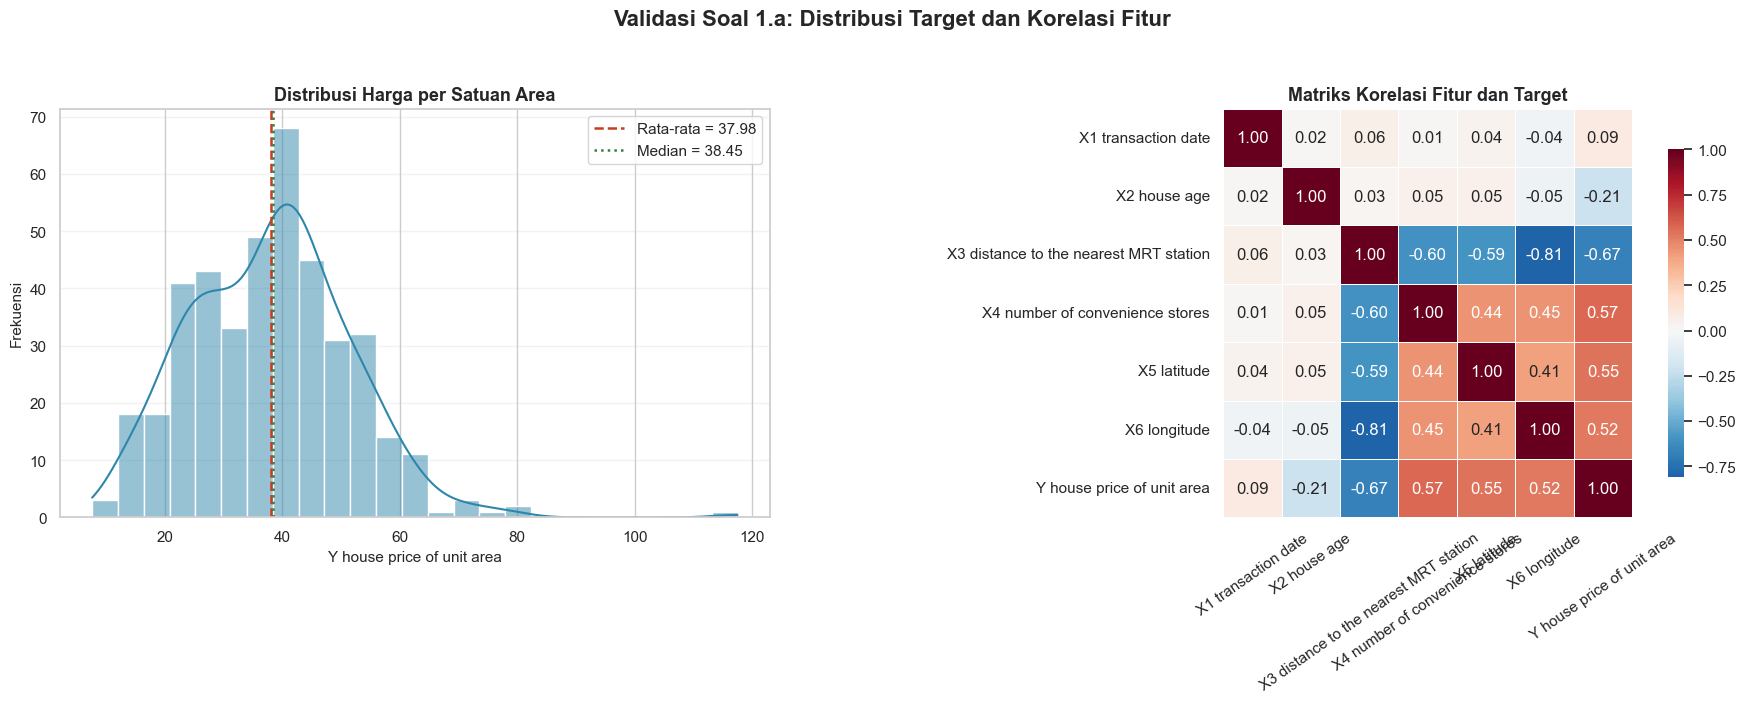

Korelasi fitur terhadap target (diurutkan berdasarkan nilai absolut):


,Korelasi dengan target
X3 distance to the nearest MRT station,-0.6736
X4 number of convenience stores,0.5710
X5 latitude,0.5463
X6 longitude,0.5233
X2 house age,-0.2106
X1 transaction date,0.0875


In [9]:
# Validasi Soal 1.a: distribusi target dan korelasi fitur-target
fig, axes = plt.subplots(1, 2, figsize=(18, 7))
fig.suptitle("Validasi Soal 1.a: Distribusi Target dan Korelasi Fitur",
             fontsize=16, fontweight="bold")

ax = axes[0]
sns.histplot(y, bins=25, kde=True, color="#2E86AB", ax=ax)
ax.axvline(y.mean(), color="#C73E1D", linestyle="--", linewidth=1.8,
           label=f"Rata-rata = {y.mean():.2f}")
ax.axvline(y.median(), color="#3A7D44", linestyle=":", linewidth=1.8,
           label=f"Median = {y.median():.2f}")
ax.set_title("Distribusi Harga per Satuan Area")
ax.set_xlabel("Y house price of unit area")
ax.set_ylabel("Frekuensi")
ax.legend(frameon=True)
ax.grid(axis="y", alpha=0.25)

ax = axes[1]
corr = df[feature_cols + [target_col]].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0,
            square=True, linewidths=0.5,
            cbar_kws={"shrink": 0.8}, ax=ax)
ax.set_title("Matriks Korelasi Fitur dan Target")
ax.tick_params(axis="x", rotation=35)
ax.tick_params(axis="y", rotation=0)

fig.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

korelasi_target = (
    corr[target_col]
    .drop(target_col)
    .sort_values(key=lambda s: s.abs(), ascending=False)
)
print("Korelasi fitur terhadap target (diurutkan berdasarkan nilai absolut):")
display(korelasi_target.to_frame("Korelasi dengan target").round(4))

#### 1.b. Persamaan regresi linier

Model Regresi Linier dilatih pada fitur yang telah distandardisasi. Intersep yang diperoleh adalah **38,3915**, dengan koefisien sebagai berikut:

| Fitur | Koefisien |
|---|---:|
| `X1 transaction date` | 1,5305 |
| `X2 house age` | -3,0627 |
| `X3 distance to the nearest MRT station` | -5,7870 |
| `X4 number of convenience stores` | 3,2190 |
| `X5 latitude` | 2,8552 |
| `X6 longitude` | -0,4412 |

Persamaan regresi linier yang terbentuk adalah:

$$\hat{y} = 38{,}3915 + 1{,}5305X_1 - 3{,}0627X_2 - 5{,}7870X_3 + 3{,}2190X_4 + 2{,}8552X_5 - 0{,}4412X_6$$

dengan $\hat{y}$ adalah prediksi harga per satuan area dan $X_1$ sampai $X_6$ adalah fitur yang telah distandardisasi (Z-score).

**Interpretasi singkat:** fitur yang paling berpengaruh adalah **jarak ke stasiun MRT (`X3`)** dengan arah negatif, diikuti oleh **jumlah minimarket (`X4`)** dan **usia rumah (`X2`)**. Artinya, properti yang lebih dekat ke MRT, berada di lingkungan dengan lebih banyak minimarket, dan berusia lebih muda cenderung memiliki harga per satuan area yang lebih tinggi.

**Validasi visual 1.b.** Grafik berikut memvalidasi persamaan regresi linier yang diperoleh. Diagram batang horizontal menunjukkan arah dan besar koefisien setiap fitur terstandardisasi. Grafik sebaran nilai aktual dan nilai prediksi menunjukkan seberapa dekat hasil prediksi model dengan nilai sebenarnya. Titik yang semakin dekat dengan garis identitas menandakan kecocokan model yang semakin baik.

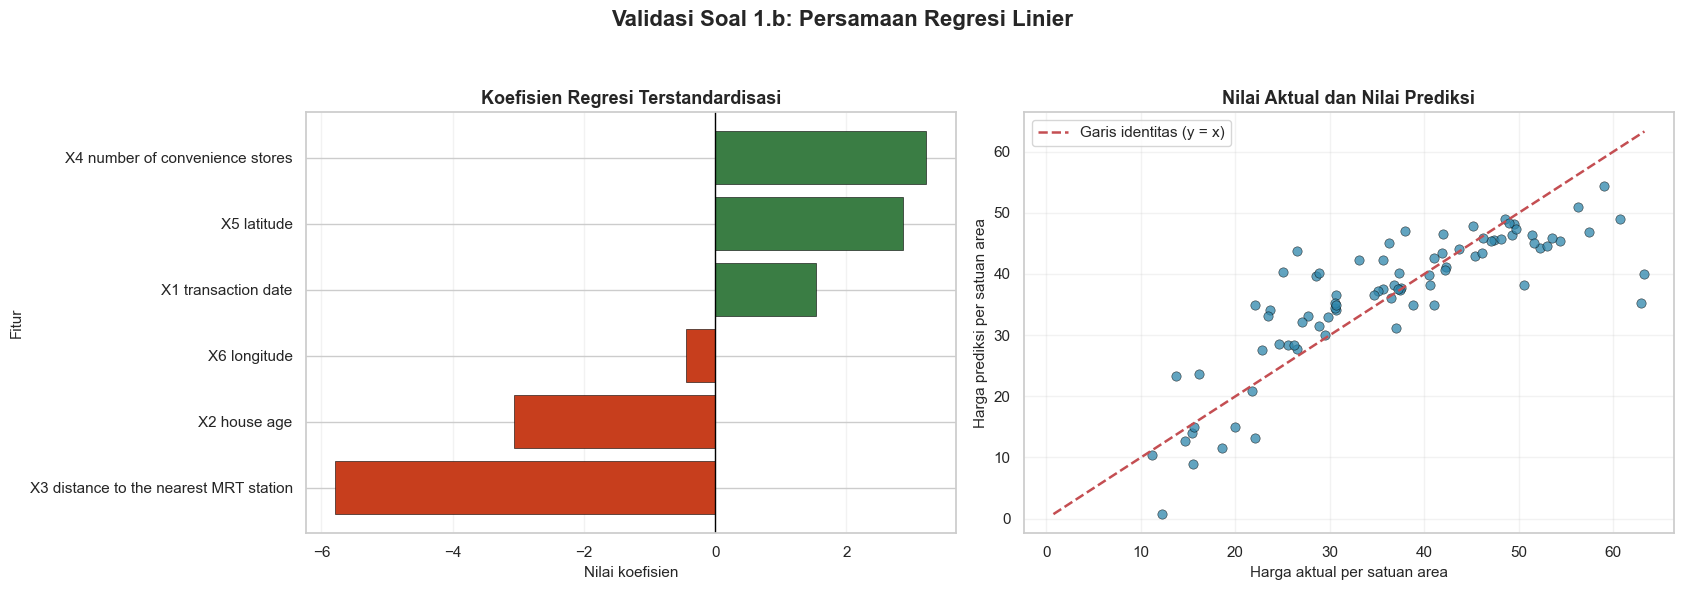

Persamaan regresi yang divalidasi:
ŷ = 38.3915 + 1.5305·X1 transaction date - 3.0627·X2 house age - 5.7870·X3 distance to the nearest MRT station + 3.2190·X4 number of convenience stores + 2.8552·X5 latitude - 0.4412·X6 longitude


In [10]:
# Validasi Soal 1.b: koefisien regresi dan kecocokan prediksi
fig, axes = plt.subplots(1, 2, figsize=(17, 6))
fig.suptitle("Validasi Soal 1.b: Persamaan Regresi Linier",
             fontsize=16, fontweight="bold")

ax = axes[0]
coef_plot = coef_df.sort_values("Koefisien")
warna_koef = ["#C73E1D" if v < 0 else "#3A7D44" for v in coef_plot["Koefisien"]]
ax.barh(coef_plot["Fitur"], coef_plot["Koefisien"], color=warna_koef,
        edgecolor="black", linewidth=0.4)
ax.axvline(0, color="black", linewidth=1)
ax.set_title("Koefisien Regresi Terstandardisasi")
ax.set_xlabel("Nilai koefisien")
ax.set_ylabel("Fitur")
ax.grid(axis="x", alpha=0.25)

ax = axes[1]
ax.scatter(y_test, y_pred_lin, alpha=0.75, s=45, color="#2E86AB",
           edgecolor="black", linewidth=0.4)
batas_lin = [
    min(float(y_test.min()), float(y_pred_lin.min())),
    max(float(y_test.max()), float(y_pred_lin.max())),
]
ax.plot(batas_lin, batas_lin, "r--", linewidth=1.8,
        label="Garis identitas (y = x)")
ax.set_title("Nilai Aktual dan Nilai Prediksi")
ax.set_xlabel("Harga aktual per satuan area")
ax.set_ylabel("Harga prediksi per satuan area")
ax.legend(frameon=True)
ax.grid(alpha=0.25)

fig.tight_layout(rect=[0, 0, 1, 0.94])
plt.show()

print("Persamaan regresi yang divalidasi:")
print(persamaan_regresi)

#### 1.c. Hasil evaluasi Regresi Linier

| Metrik | Nilai |
|---|---:|
| RMSE | 7,3145 |
| MAE | 5,3052 |
| MAPE | 17,18% |
| R² | 0,6811 |

**Interpretasi:** model Regresi Linier mampu menjelaskan sekitar **68,11%** varians harga per satuan area pada data uji. Rata-rata kesalahan absolut sebesar **5,3052** satuan, sedangkan kesalahan relatif rata-rata sebesar **17,18%**. Nilai ini menunjukkan performa yang cukup baik, tetapi masih menyisakan ruang perbaikan karena hubungan data tidak sepenuhnya linier.

**Validasi visual 1.c.** Grafik berikut memvalidasi nilai RMSE, MAE, MAPE, dan R², serta memeriksa pola residual model. Empat panel pertama menampilkan nilai setiap metrik evaluasi. Panel residual terhadap nilai prediksi dan histogram residual digunakan untuk melihat apakah kesalahan model tersebar acak di sekitar nol. Residual yang menyebar acak dan simetris menunjukkan bahwa model tidak memiliki bias sistematis yang jelas.

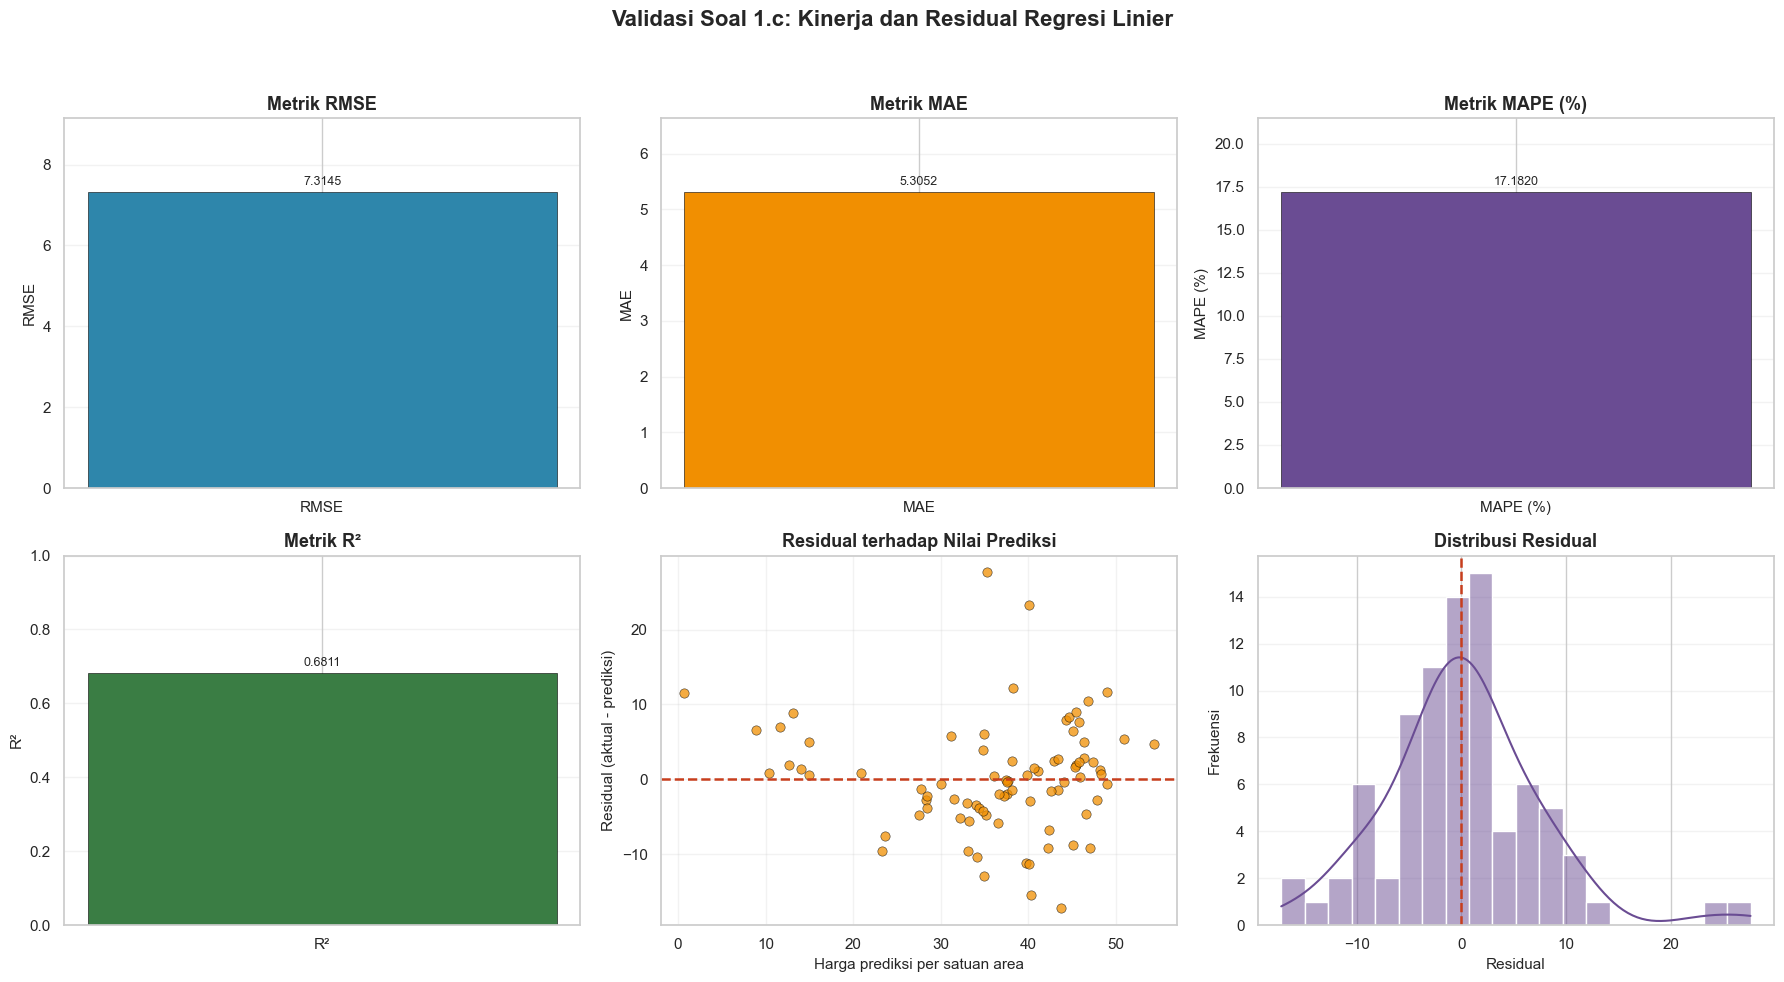

Ringkasan residual Regresi Linier:
Rata-rata residual      : 0.1237
Simpangan baku residual : 7.3135
Residual minimum        : -17.2219
Residual maksimum       : 27.6322


In [11]:
# Validasi Soal 1.c: metrik evaluasi dan residual
residual_lin = y_test.values - y_pred_lin

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle("Validasi Soal 1.c: Kinerja dan Residual Regresi Linier",
             fontsize=16, fontweight="bold")

metrik_panel = [
    ("RMSE", metrics_lin["RMSE"], "#2E86AB"),
    ("MAE", metrics_lin["MAE"], "#F18F01"),
    ("MAPE (%)", metrics_lin["MAPE (%)"], "#6A4C93"),
    ("R²", metrics_lin["R²"], "#3A7D44"),
]

for ax, (label, nilai, warna) in zip(axes.ravel()[:4], metrik_panel):
    bar = ax.bar([label], [nilai], color=warna, edgecolor="black", linewidth=0.4)
    ax.set_title(f"Metrik {label}")
    ax.set_ylabel(label)
    ax.bar_label(bar, fmt="%.4f", padding=3, fontsize=9)
    ax.set_ylim(0, 1.0 if label == "R²" else max(nilai * 1.25, 1.0))
    ax.grid(axis="y", alpha=0.25)

ax = axes[1, 1]
ax.scatter(y_pred_lin, residual_lin, alpha=0.75, s=45, color="#F18F01",
           edgecolor="black", linewidth=0.4)
ax.axhline(0, color="#C73E1D", linestyle="--", linewidth=1.8)
ax.set_title("Residual terhadap Nilai Prediksi")
ax.set_xlabel("Harga prediksi per satuan area")
ax.set_ylabel("Residual (aktual - prediksi)")
ax.grid(alpha=0.25)

ax = axes[1, 2]
sns.histplot(residual_lin, bins=20, kde=True, color="#6A4C93", ax=ax)
ax.axvline(0, color="#C73E1D", linestyle="--", linewidth=1.8)
ax.set_title("Distribusi Residual")
ax.set_xlabel("Residual")
ax.set_ylabel("Frekuensi")
ax.grid(axis="y", alpha=0.25)

fig.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

print("Ringkasan residual Regresi Linier:")
print(f"Rata-rata residual      : {residual_lin.mean():.4f}")
print(f"Simpangan baku residual : {residual_lin.std():.4f}")
print(f"Residual minimum        : {residual_lin.min():.4f}")
print(f"Residual maksimum       : {residual_lin.max():.4f}")

### Soal 2: Perbandingan k-NN untuk k = 2, 3, 5, 7, dan 9

| Model | RMSE | MAE | MAPE (%) | R² |
|---|---:|---:|---:|---:|
| k-NN (k = 2) | 6,7730 | 4,8120 | 14,11 | 0,7266 |
| k-NN (k = 3) | 6,9521 | 4,7036 | 13,59 | 0,7119 |
| **k-NN (k = 5)** | **6,4032** | **4,5280** | **13,44** | **0,7556** |
| k-NN (k = 7) | 6,6860 | 4,7103 | 14,39 | 0,7335 |
| k-NN (k = 9) | 6,4752 | 4,6940 | 14,56 | 0,7501 |

**Pembahasan:**

- **k = 5** merupakan konfigurasi terbaik berdasarkan **RMSE terkecil (6,4032)**, **MAPE terendah (13,44%)**, dan **R² tertinggi (0,7556)**.
- **k = 3** memiliki **MAE terkecil (4,7036)**, tetapi nilai RMSE dan R² lebih rendah daripada k = 5. Hal ini menunjukkan bahwa k = 3 masih menghasilkan beberapa kesalahan besar meskipun rata-rata kesalahan absolutnya kecil.
- **k = 2** memiliki varians tinggi karena hanya menggunakan dua tetangga, sehingga rentan terhadap *noise* dan *outlier*.
- **k = 7** dan **k = 9** mulai mengalami *oversmoothing*; prediksi menjadi lebih halus, tetapi detail pola lokal berkurang sehingga RMSE meningkat kembali.
- Secara keseluruhan, **k = 5 memberikan keseimbangan bias dan varians terbaik** pada dataset ini.

**Validasi visual Soal 2.** Grafik berikut memvalidasi perbandingan kinerja k-NN untuk setiap nilai k. Setiap panel menampilkan satu metrik, sedangkan garis putus-putus menunjukkan nilai pembanding Regresi Linier. Titik yang ditandai bintang menunjukkan nilai k terbaik pada metrik tersebut. Pola grafik memperlihatkan pengaruh nilai k terhadap akurasi dan membantu menjelaskan trade-off antara bias dan varians.

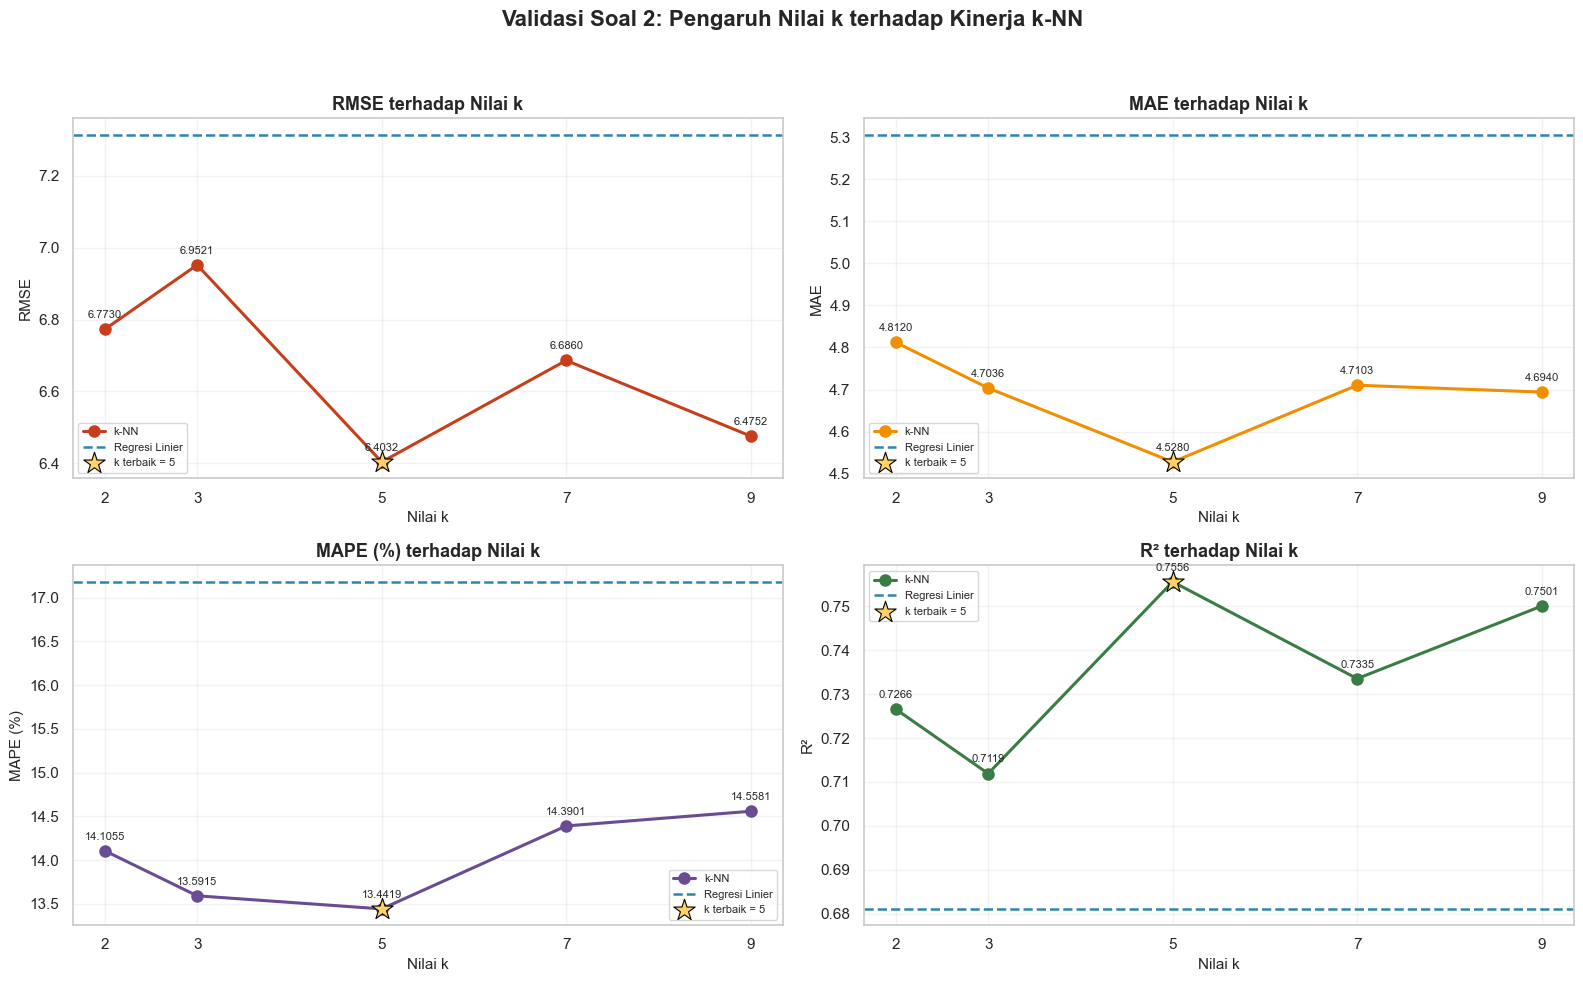

In [12]:
# Validasi Soal 2: pengaruh nilai k terhadap setiap metrik
k_axis = [int(m.split("=")[1].rstrip(")")) for m in tabel_knn["Model"]]
metrik_knn = [
    ("RMSE", "RMSE", "#C73E1D", "min"),
    ("MAE", "MAE", "#F18F01", "min"),
    ("MAPE (%)", "MAPE (%)", "#6A4C93", "min"),
    ("R²", "R²", "#3A7D44", "max"),
]

fig, axes = plt.subplots(2, 2, figsize=(16, 10))
fig.suptitle("Validasi Soal 2: Pengaruh Nilai k terhadap Kinerja k-NN",
             fontsize=16, fontweight="bold")

for ax, (kolom, label, warna, arah) in zip(axes.ravel(), metrik_knn):
    nilai = tabel_knn[kolom].to_numpy()
    ax.plot(k_axis, nilai, marker="o", markersize=8, linewidth=2.2,
            color=warna, label="k-NN")
    ax.axhline(metrics_lin[kolom], color="#2E86AB", linestyle="--",
               linewidth=1.8, label="Regresi Linier")
    idx_best = int(np.argmin(nilai) if arah == "min" else np.argmax(nilai))
    ax.scatter(k_axis[idx_best], nilai[idx_best], marker="*", s=260,
               color="#FFD166", edgecolor="black", linewidth=0.8, zorder=5,
               label=f"k terbaik = {k_axis[idx_best]}")
    for x_val, y_val in zip(k_axis, nilai):
        ax.annotate(f"{y_val:.4f}", (x_val, y_val), textcoords="offset points",
                    xytext=(0, 8), ha="center", fontsize=8)
    ax.set_title(f"{label} terhadap Nilai k")
    ax.set_xlabel("Nilai k")
    ax.set_ylabel(label)
    ax.set_xticks(k_axis)
    ax.legend(frameon=True, fontsize=8)
    ax.grid(alpha=0.25)

fig.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

### Soal 3: Model terbaik dan alasannya

**Model terbaik adalah k-NN dengan k = 5.**

| Metrik | Regresi Linier | k-NN (k = 5) | Selisih |
|---|---:|---:|---:|
| RMSE | 7,3145 | **6,4032** | -0,9113 |
| MAE | 5,3052 | **4,5280** | -0,7773 |
| MAPE (%) | 17,18 | **13,44** | -3,74 |
| R² | 0,6811 | **0,7556** | +0,0745 |

**Alasan pemilihan:**

1. **Akurasi metrik:** k-NN (k = 5) menghasilkan RMSE, MAE, dan MAPE terendah serta R² tertinggi pada data uji yang sama. Penurunan RMSE sebesar **12,46%** dan kenaikan R² sebesar **0,0745** menunjukkan peningkatan yang nyata dibandingkan Regresi Linier.
2. **Pola nonlinier dan spasial:** data harga properti tidak sepenuhnya mengikuti hubungan linier. Pengaruh jarak ke MRT, lokasi (`latitude`/`longitude`), dan interaksi antarfitur lebih tepat ditangkap melalui kemiripan lokal yang digunakan k-NN.
3. **Trade-off antara bias dan varians:** k = 5 memberikan keseimbangan terbaik. Nilai k terlalu kecil (k = 2) menyebabkan varians dan overfitting, sedangkan nilai k terlalu besar (k = 9) menyebabkan oversmoothing dan underfitting.
4. **Pertimbangan praktis:** k-NN (k = 5) lebih akurat untuk prediksi, tetapi memerlukan penskalaan fitur dan biaya komputasi prediksi yang lebih tinggi serta tidak memberikan persamaan eksplisit. Regresi Linier tetap lebih unggul dalam interpretabilitas. Dengan demikian, untuk tujuan **prediksi harga**, k-NN (k = 5) dipilih sebagai model terbaik; untuk tujuan **penjelasan pengaruh fitur**, Regresi Linier dapat digunakan sebagai pendamping.

**Validasi visual Soal 3.** Tabel selisih metrik menunjukkan besar perbaikan model terbaik terhadap Regresi Linier. Grafik batang membandingkan metrik kesalahan secara langsung, sedangkan grafik aktual dan prediksi serta histogram residual memvalidasi kualitas prediksi model terbaik pada data uji. Semakin dekat titik ke garis identitas dan semakin simetris residual di sekitar nol, semakin baik kualitas prediksi.

Selisih kinerja model terbaik terhadap Regresi Linier:


,Metrik,Regresi Linier,k-NN (k=5),Selisih,Perbaikan Relatif (%)
0,RMSE,7.3145,6.4032,-0.9113,12.4594
1,MAE,5.3052,4.5280,-0.7773,14.6512
2,MAPE (%),17.1820,13.4419,-3.7402,21.7680
3,R²,0.6811,0.7556,0.0745,10.9416


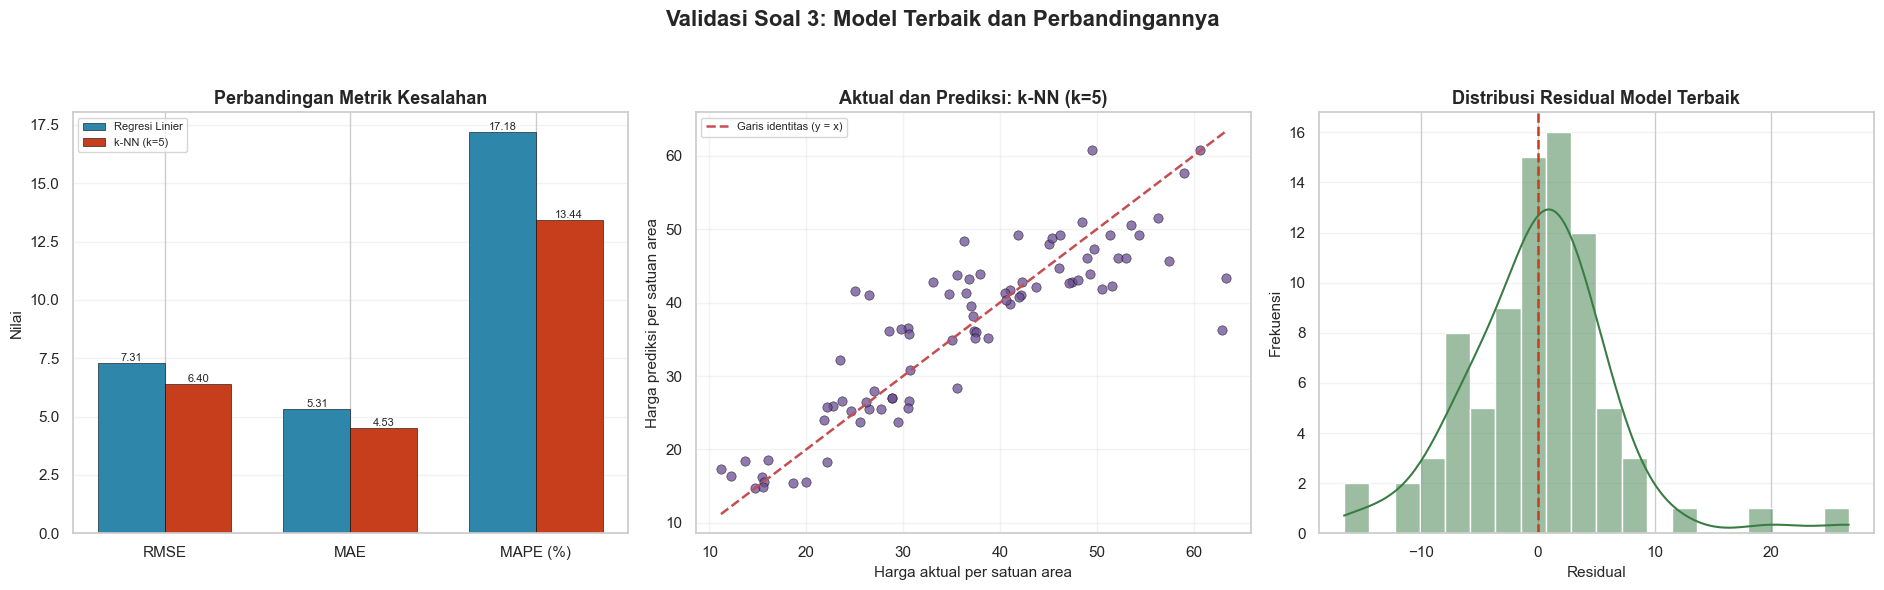

In [13]:
# Validasi Soal 3: selisih kinerja dan kualitas prediksi model terbaik
metrik_urut = ["RMSE", "MAE", "MAPE (%)", "R²"]
selisih_df = pd.DataFrame({
    "Metrik": metrik_urut,
    "Regresi Linier": [metrics_lin[m] for m in metrik_urut],
    best_model_name: [best_metrics[m] for m in metrik_urut],
})
selisih_df["Selisih"] = (
    selisih_df[best_model_name] - selisih_df["Regresi Linier"]
)
selisih_df["Perbaikan Relatif (%)"] = np.where(
    selisih_df["Metrik"] == "R²",
    selisih_df["Selisih"] / selisih_df["Regresi Linier"] * 100,
    -selisih_df["Selisih"] / selisih_df["Regresi Linier"] * 100,
)

print("Selisih kinerja model terbaik terhadap Regresi Linier:")
display(selisih_df.round(4))

residual_best = y_test.values - y_pred_best

fig, axes = plt.subplots(1, 3, figsize=(19, 6))
fig.suptitle("Validasi Soal 3: Model Terbaik dan Perbandingannya",
             fontsize=16, fontweight="bold")

ax = axes[0]
x_metrik = np.arange(3)
w_metrik = 0.36
nilai_lin = [metrics_lin[m] for m in ["RMSE", "MAE", "MAPE (%)"]]
nilai_best = [best_metrics[m] for m in ["RMSE", "MAE", "MAPE (%)"]]
ax.bar(x_metrik - w_metrik/2, nilai_lin, w_metrik, label="Regresi Linier",
       color="#2E86AB", edgecolor="black", linewidth=0.4)
ax.bar(x_metrik + w_metrik/2, nilai_best, w_metrik, label=best_model_name,
       color="#C73E1D", edgecolor="black", linewidth=0.4)
ax.set_xticks(x_metrik)
ax.set_xticklabels(["RMSE", "MAE", "MAPE (%)"])
ax.set_title("Perbandingan Metrik Kesalahan")
ax.set_ylabel("Nilai")
ax.legend(frameon=True, fontsize=8)
ax.grid(axis="y", alpha=0.25)
for i, (v_lin, v_best) in enumerate(zip(nilai_lin, nilai_best)):
    ax.text(i - w_metrik/2, v_lin, f"{v_lin:.2f}",
            ha="center", va="bottom", fontsize=8)
    ax.text(i + w_metrik/2, v_best, f"{v_best:.2f}",
            ha="center", va="bottom", fontsize=8)

ax = axes[1]
ax.scatter(y_test, y_pred_best, alpha=0.75, s=45, color="#6A4C93",
           edgecolor="black", linewidth=0.4)
batas_best = [
    min(float(y_test.min()), float(y_pred_best.min())),
    max(float(y_test.max()), float(y_pred_best.max())),
]
ax.plot(batas_best, batas_best, "r--", linewidth=1.8,
        label="Garis identitas (y = x)")
ax.set_title(f"Aktual dan Prediksi: {best_model_name}")
ax.set_xlabel("Harga aktual per satuan area")
ax.set_ylabel("Harga prediksi per satuan area")
ax.legend(frameon=True, fontsize=8)
ax.grid(alpha=0.25)

ax = axes[2]
sns.histplot(residual_best, bins=20, kde=True, color="#3A7D44", ax=ax)
ax.axvline(0, color="#C73E1D", linestyle="--", linewidth=1.8)
ax.set_title("Distribusi Residual Model Terbaik")
ax.set_xlabel("Residual")
ax.set_ylabel("Frekuensi")
ax.grid(axis="y", alpha=0.25)

fig.tight_layout(rect=[0, 0, 1, 0.94])
plt.show()

### Catatan Validitas Metodologis

- Data uji tidak digunakan pada proses pelatihan maupun penskalaan.
- `StandardScaler` di-*fit* hanya pada data latih, lalu diterapkan pada data uji.
- Seluruh model dievaluasi pada data uji yang identik dengan pembagian data dan *random state* yang sama.
- Perbandingan model dilakukan secara adil karena tidak ada perbedaan data, target, maupun metrik evaluasi.

### Lampiran: Validasi Ringkasan Akhir

Tabel dan grafik berikut memvalidasi rekapitulasi jawaban akhir. Model terbaik ditandai dengan warna merah, sedangkan model pembanding ditandai dengan warna biru. Grafik RMSE dan R² memperlihatkan posisi setiap model secara keseluruhan sehingga kesimpulan pada Tahap 9 dapat diperiksa kembali secara visual.

Tabel validasi ringkasan seluruh model:


,Model,RMSE,MAE,MAPE (%),R²,Keterangan
0,Regresi Linier,7.3145,5.3052,17.1820,0.6811,Pembanding
1,k-NN (k=2),6.7730,4.8120,14.1055,0.7266,Pembanding
2,k-NN (k=3),6.9521,4.7036,13.5915,0.7119,Pembanding
3,k-NN (k=5),6.4032,4.5280,13.4419,0.7556,Model terbaik
4,k-NN (k=7),6.6860,4.7103,14.3901,0.7335,Pembanding
5,k-NN (k=9),6.4752,4.6940,14.5581,0.7501,Pembanding


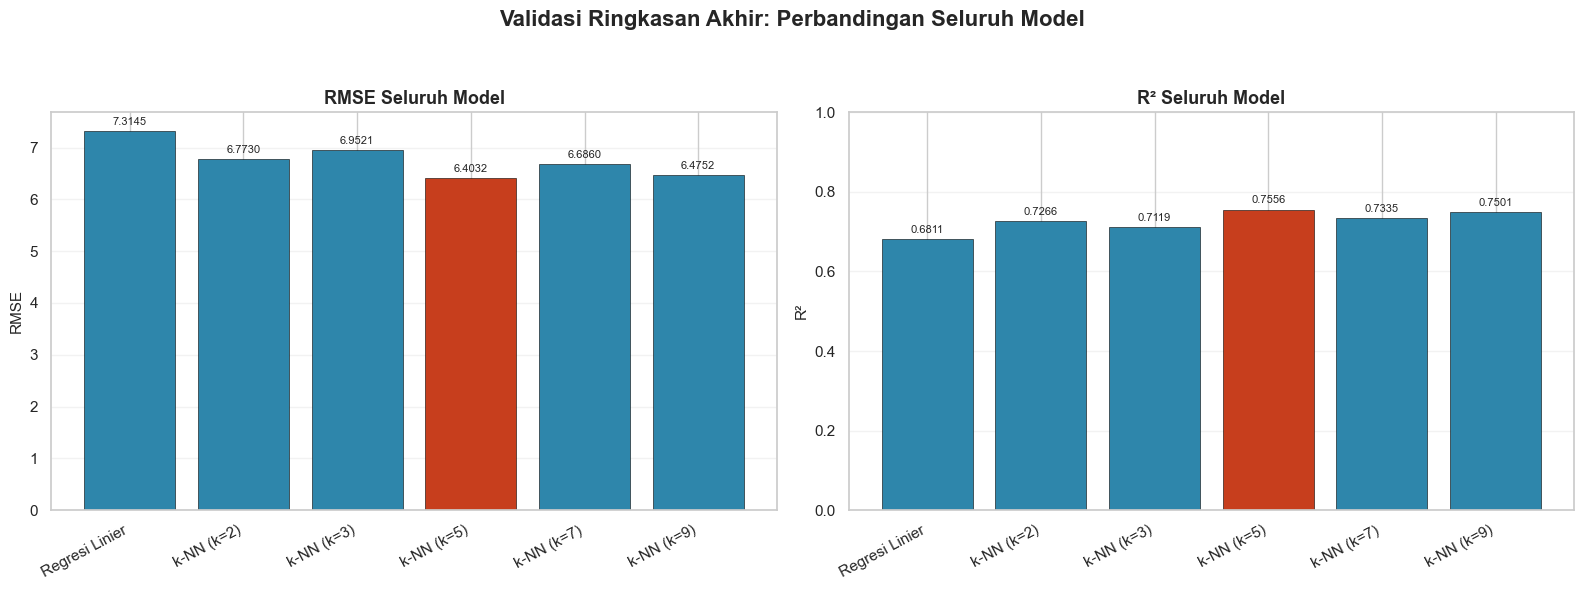

In [14]:
# Validasi ringkasan akhir: seluruh model dan model terbaik
ringkasan = results_all.copy()
ringkasan["Keterangan"] = np.where(
    ringkasan["Model"] == best_model_name, "Model terbaik", "Pembanding"
)

print("Tabel validasi ringkasan seluruh model:")
display(ringkasan.round(4))

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle("Validasi Ringkasan Akhir: Perbandingan Seluruh Model",
             fontsize=16, fontweight="bold")

warna_model = [
    "#C73E1D" if m == best_model_name else "#2E86AB"
    for m in results_all["Model"]
]

ax = axes[0]
bar_rmse = ax.bar(results_all["Model"], results_all["RMSE"],
                  color=warna_model, edgecolor="black", linewidth=0.4)
ax.set_xticks(range(len(results_all)))
ax.set_xticklabels(results_all["Model"], rotation=28, ha="right")
ax.set_ylabel("RMSE")
ax.set_title("RMSE Seluruh Model")
ax.bar_label(bar_rmse, fmt="%.4f", padding=3, fontsize=8)
ax.grid(axis="y", alpha=0.25)

ax = axes[1]
bar_r2 = ax.bar(results_all["Model"], results_all["R²"],
                color=warna_model, edgecolor="black", linewidth=0.4)
ax.set_xticks(range(len(results_all)))
ax.set_xticklabels(results_all["Model"], rotation=28, ha="right")
ax.set_ylabel("R²")
ax.set_ylim(0, 1.0)
ax.set_title("R² Seluruh Model")
ax.bar_label(bar_r2, fmt="%.4f", padding=3, fontsize=8)
ax.grid(axis="y", alpha=0.25)

fig.tight_layout(rect=[0, 0, 1, 0.94])
plt.show()